# Mean reversion: testramverk

**Syfte:** ta reda på om en datamängd beter sig som mean reverting *innan* du lägger tid på att bygga en strategi.

**Så använder du den**
1. Ändra inställningarna i första kodcellen, främst `PRICES_FILE`.
2. Kör alla celler (cirka 1 minut).
3. Läs **Sammanfattningen** längst ned. Gå sedan tillbaka till testen och sliders för detaljer.

**Testerna**

| Test | Fråga | Styrka | Svaghet |
|---|---|---|---|
| **1. Autokorrelation per horisont** | Brukar en rörelse de senaste h dagarna följas av en rörelse åt *motsatt* håll de kommande h dagarna? | Täcker alla horisonter 1–300 dagar | Linjärt mått på alla dagar, och få oberoende fall vid långa horisonter |
| **2. Händelsestudie** | Vad händer efter en *stor* rörelse (chock)? | Hittar effekter som bara finns efter stora rörelser | Färre fall ju större och längre chockerna är |
| **3. Chockkarta** | Hur många chocker finns det, var ligger de och hur *ofta* går de tillbaka? | Visar om effekten handlar om storlek eller frekvens | Per tillgång blir det ofta få fall |
| **4. Episoder och förlustsida** | Om man går emot varje chock tills priset gått tillbaka till nivå Y: tjänar man pengar i snitt, och hur stora blir förlusterna när det *inte* går tillbaka? | Mäter faktisk vinst per affär, med kostnad och stop | Bygger på valda nivåer (Y, stop, max dagar), så risk för överanpassning |

**Gemensam princip:** allt jämförs med **blandad data**, där dagarnas ordning slumpas så att alla mönster i tiden försvinner. Om resultatet inte är bättre än vad slumpen ger finns ingen mean reversion att handla på.

Strategidelen (bygga, utvärdera och riskjustera) finns i `mean_reversion_short_strategy.ipynb`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

notebook_file = globals().get("__vsc_ipynb_file__")
NOTEBOOK_DIR = Path(notebook_file).resolve().parent if notebook_file else Path.cwd()
sys.path.insert(0, str(NOTEBOOK_DIR))

DATE = "AsOfDate"

# ------------------------------------------------------------------ INSTÄLLNINGAR
PRICES_FILE = "example_prices.csv"   # byt till den riktiga datan
VOL_WINDOW = 100                     # dagar för volatilitetsskattningen
MAX_HORIZON = 300                    # längsta horisont i test 1
N_SHUFFLE = 100                      # blandningar per tillgång i test 1 (fler = stabilare band, långsammare)
N_NULL = 200                         # blandningar i test 2 och 3
SHOCK_L, SHOCK_K, SHOCK_H = 1, 3.0, 20   # standardchock: > SHOCK_K std på SHOCK_L dagar, utfall efter SHOCK_H dagar
EPISODE_Y = 0.5                      # test 4: mål = så stor andel av chocken har gått tillbaka (0.5 = halva)
EPISODE_MAX_DAYS = 60                # test 4: stäng affären senast efter så många dagar
STOP_LOSS = None                     # test 4: failsafe, stäng vid så stor orealiserad förlust (dagliga std). None = av
COST = -0.02                         # kostnad per handlad enhet i dagliga std (som evaluation.py)
# ---------------------------------------------------------------------------------

prices = pl.read_csv(NOTEBOOK_DIR / PRICES_FILE, try_parse_dates=True).rename({"dates": DATE})
instruments = [c for c in prices.columns if c != DATE]
ret = prices.select(DATE, pl.col(instruments).diff())
vol = ret.select(DATE, pl.col(instruments).pow(2).rolling_mean(VOL_WINDOW, min_samples=10).sqrt().shift(1))
norm_ret = ret.select(DATE, *[(pl.col(c) / vol[c]).fill_nan(None).alias(c) for c in instruments])

print(f"{prices.height} dagar, {prices[DATE][0]} till {prices[DATE][-1]}, tillgångar: {instruments}")
print("Std för normaliserad avkastning (ska vara nära 1):")
print(norm_ret.select(pl.col(instruments).std()))

5956 dagar, 2000-01-03 till 2023-01-11, tillgångar: ['diamonds', 'butter', 'cars', 'cucumber', 'bananas']
Std för normaliserad avkastning (ska vara nära 1):
shape: (1, 5)
┌──────────┬─────────┬──────────┬──────────┬──────────┐
│ diamonds ┆ butter  ┆ cars     ┆ cucumber ┆ bananas  │
│ ---      ┆ ---     ┆ ---      ┆ ---      ┆ ---      │
│ f64      ┆ f64     ┆ f64      ┆ f64      ┆ f64      │
╞══════════╪═════════╪══════════╪══════════╪══════════╡
│ 1.022204 ┆ 1.01673 ┆ 1.020913 ┆ 1.015677 ┆ 1.024953 │
└──────────┴─────────┴──────────┴──────────┴──────────┘


## Test 1: Autokorrelation per tillgång och tidshorisont

**Frågan:** om en tillgång har gått upp de senaste **h** dagarna, brukar den då gå ner de **kommande h** dagarna?

Det mäter vi med **autokorrelation**: korrelationen mellan prisförändringen de senaste h dagarna (`pris idag − pris för h dagar sedan`) och de kommande h dagarna. Det är samma block-autokorrelation som i `modeling_example`, men per tillgång och för horisonter upp till `MAX_HORIZON` dagar.
- **Negativ** korrelation = mean reversion (priset går tillbaka)
- **Positiv** korrelation = trend (priset fortsätter)
- Framtidsfönstret börjar **dag t+2**, eftersom det är då en position faktiskt börjar tjäna pengar.

### Det grå bandet = vad ren slump kan ge
1. Vi **blandar dagarnas ordning** slumpmässigt. Då försvinner alla mönster i tiden, men avkastningarnas storlek och fördelning (inklusive extrema dagar) är kvar.
2. På den blandade datan räknar vi **exakt samma** autokorrelation, för alla horisonter.
3. Vi upprepar det 100 gånger per tillgång och slår ihop tillgångarna, eftersom de är normaliserade till samma skala. Det ger 500 slumputfall per horisont.
4. Bandet visar var **95 %** av slumputfallen hamnar (2,5- och 97,5-percentilen). Den prickade linjen är slumpens median.

**Varför bandet inte är centrerat kring 0:** när fönstren är långa finns få oberoende perioder (h = 200 ger cirka 30 på 23 år). Då blir korrelationen i genomsnitt **negativ även för ren slump**, och fördelningen blir sned. Ett band på ±2 std runt 0 skulle därför göra det för lätt att hitta mean reversion och för svårt att hitta trend. Percentilerna tar hand om det automatiskt.

**Varför vi blandar i stället för att använda en formel:** fönstren överlappar, eftersom vi glider fram en dag i taget. Det gör att vanliga formler för standardfel blir fel. Eftersom blandningen räknar samma överlappande statistik, blir felet rätt hanterat.

In [2]:
HORIZONS = np.arange(1, MAX_HORIZON + 1)
GAP = 1          # framtidsfönstret startar dag t+2 (1 dags glapp efter t+1)

X = norm_ret.select(instruments).drop_nulls().to_numpy()
T, M = X.shape


def past_future(S: np.ndarray, h: int, gap: int = GAP):
    # S = kumulativ summa ("volatilitetsjusterat pris") med en nolla först.
    # past = prisförändring de h senaste dagarna (t.o.m. t), future = h dagar med start t+1+gap.
    a = np.arange(h, T - h - gap + 1)
    return S[a] - S[a - h], S[a + gap + h] - S[a + gap]


def corr_cols(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    x = x - x.mean(axis=0)
    y = y - y.mean(axis=0)
    return (x * y).sum(axis=0) / np.sqrt((x**2).sum(axis=0) * (y**2).sum(axis=0))


def horizon_autocorr(X: np.ndarray) -> np.ndarray:
    S = np.vstack([np.zeros(X.shape[1]), np.cumsum(X, axis=0)])
    return np.array([corr_cols(*past_future(S, h)) for h in HORIZONS])   # (horisonter, tillgångar)


ac = horizon_autocorr(X)

# Slumputfall: blanda varje tillgångs dagar oberoende, N_SHUFFLE gånger (~30 s)
rng = np.random.default_rng(0)
null = np.stack([horizon_autocorr(np.column_stack([rng.permutation(X[:, j]) for j in range(M)]))
                 for _ in range(N_SHUFFLE)])                              # (N_SHUFFLE, horisonter, tillgångar)
pooled = null.transpose(0, 2, 1).reshape(-1, len(HORIZONS))              # (N_SHUFFLE * M, horisonter)
null_lo, null_mid, null_hi = np.percentile(pooled, [2.5, 50, 97.5], axis=0)
null_std = pooled.std(axis=0, ddof=1)
S_real = np.vstack([np.zeros(M), np.cumsum(X, axis=0)])

# Hur skev är slumpen? (jämför med ett naivt ±2 std-band runt 0)
pl.DataFrame([{"h": h, "slumpens median": round(null_mid[h - 1], 3),
               "2,5 %": round(null_lo[h - 1], 3), "97,5 %": round(null_hi[h - 1], 3),
               "naivt ±2 std": round(2 * null_std[h - 1], 3)} for h in [5, 50, 100, 200, 300]])

h,slumpens median,"2,5 %","97,5 %",naivt ±2 std
i64,f64,f64,f64,f64
5,-0.003,-0.046,0.042,0.047
50,-0.005,-0.15,0.125,0.142
100,-0.029,-0.238,0.156,0.204
200,-0.057,-0.329,0.222,0.284
300,-0.075,-0.421,0.262,0.349


### Översikt: var finns mean reversion respektive trend?
Tabellen visar horisonter där korrelationen ligger **under** bandet (mean reversion) eller **över** bandet (trend).

In [3]:
def ranges(hs):
    if len(hs) == 0:
        return "–"
    out, start, prev = [], hs[0], hs[0]
    for h in hs[1:]:
        if h != prev + 1:
            out.append(f"{start}-{prev}" if start != prev else f"{start}")
            start = h
        prev = h
    out.append(f"{start}-{prev}" if start != prev else f"{start}")
    return ", ".join(out)


pl.DataFrame([{
    "tillgång": c,
    "mean reversion (dagar)": ranges(HORIZONS[ac[:, j] < null_lo].tolist()),
    "trend (dagar)": ranges(HORIZONS[ac[:, j] > null_hi].tolist()),
    "starkast reversion": f"h={HORIZONS[ac[:, j].argmin()]}, corr={ac[:, j].min():.2f}",
} for j, c in enumerate(instruments)])

tillgång,mean reversion (dagar),trend (dagar),starkast reversion
str,str,str,str
"""diamonds""","""130-238""","""–""","""h=200, corr=-0.40"""
"""butter""","""4-7""","""1, 21-69, 103-107, 110-300""","""h=6, corr=-0.06"""
"""cars""","""–""","""8-79""","""h=300, corr=-0.13"""
"""cucumber""","""–""","""7-8, 10-32""","""h=170, corr=-0.13"""
"""bananas""","""–""","""18-43""","""h=105, corr=-0.06"""


### Kan resultatet vara tur? (många tester samtidigt)
Bandet gäller **en horisont i taget**. Vi tittar på 300 horisonter × flera tillgångar, så några punkter hamnar utanför bandet av ren slump. Därför frågar vi slumpdatan två saker:

1. **Längsta område:** hur ofta ger slumpen ett *lika långt sammanhängande* område under bandet?
2. **Starkaste punkt:** hur ofta ger slumpen en *lika stark* punkt (i standardavvikelser) någonstans bland alla 300 horisonter?

Båda frågorna besvaras för *en tillgång som valts i förväg* och för *bästa av alla tillgångar*. Det senare är det ärliga måttet om man har letat igenom alla.

In [4]:
def longest_run(mask: np.ndarray) -> int:
    best = cur = 0
    for m in mask:
        cur = cur + 1 if m else 0
        best = max(best, cur)
    return best


null_runs = np.array([[longest_run(null[k, :, j] < null_lo) for j in range(M)] for k in range(N_SHUFFLE)])
z_null_min = ((null - null_mid[None, :, None]) / null_std[None, :, None]).min(axis=1)   # (N_SHUFFLE, M)

rows = []
for j, c in enumerate(instruments):
    run = longest_run(ac[:, j] < null_lo)
    z = ((ac[:, j] - null_mid) / null_std).min()
    rows.append({
        "tillgång": c,
        "längsta område (dagar)": run,
        "P(slump, en tillgång)": round(float((null_runs >= run).mean()), 3) if run else None,
        f"P(slump, bästa av {M})": round(float((null_runs.max(axis=1) >= run).mean()), 3) if run else None,
        "starkaste punkt (std)": round(float(z), 2),
        "P(slump, en tillgång) ": round(float((z_null_min <= z).mean()), 3),
        f"P(slump, bästa av {M}) ": round(float((z_null_min.min(axis=1) <= z).mean()), 3),
    })
pl.DataFrame(rows)

tillgång,längsta område (dagar),"P(slump, en tillgång)","P(slump, bästa av 5)",starkaste punkt (std),"P(slump, en tillgång)","P(slump, bästa av 5)"
str,i64,f64,f64,f64,f64,f64
"""diamonds""",109,0.016,0.08,-2.51,0.078,0.33
"""butter""",4,0.18,0.62,-2.42,0.094,0.38
"""cars""",0,null,null,-0.37,0.954,1.0
"""cucumber""",0,null,null,-0.75,0.882,1.0
"""bananas""",0,null,null,-1.15,0.706,1.0


**Hänger resultatet på en enda period?** För tillgången med starkast mean reversion tar vi bort två år i taget och räknar om korrelationen. Om ett enskilt boom/bust-förlopp låg bakom resultatet skulle det försvinna när just de åren tas bort.

In [5]:
j_best = int(ac.min(axis=0).argmin())
h_best = int(HORIZONS[ac[:, j_best].argmin()])
a = np.arange(h_best, T - h_best)
past = S_real[a, j_best] - S_real[a - h_best, j_best]
fut = S_real[a + 1 + h_best, j_best] - S_real[a + 1, j_best]
dates_x = norm_ret.drop_nulls()[DATE]
rows = [{"utan perioden": "– (all data)", "korrelation": round(float(np.corrcoef(past, fut)[0, 1]), 3)}]
chunk = 520   # cirka 2 år
for s in range(0, T, chunk):
    keep = (a + 1 + h_best < s) | (a - h_best >= s + chunk)
    rows.append({"utan perioden": f"{dates_x[s].year}–{dates_x[min(s + chunk, T) - 1].year}",
                 "korrelation": round(float(np.corrcoef(past[keep], fut[keep])[0, 1]), 3)})
print(f"{instruments[j_best]}, h = {h_best}")
pl.DataFrame(rows)

diamonds, h = 200


utan perioden,korrelation
str,f64
"""– (all data)""",-0.396
"""2000–2002""",-0.398
"""2002–2004""",-0.364
"""2004–2006""",-0.33
"""2006–2008""",-0.393
…,…
"""2014–2016""",-0.489
"""2016–2018""",-0.432
"""2018–2020""",-0.389


### Slider: välj tidshorisont
En rad per tillgång.
- **Vänster:** autokorrelationen för alla horisonter (svart), slumpbandet (grått) och slumpens median (prickad). Den streckade linjen är vald horisont.
- **Höger:** varje punkt är ett tillfälle. x = prisförändring de senaste h dagarna, y = de kommande h dagarna (i volatilitetsenheter). En **nedåtlutande** linje betyder mean reversion. För att det ska gå att se något visas bara icke-överlappande punkter, men linjen och korrelationen räknas på all data.

In [6]:
from ipywidgets import IntSlider, interact

COLORS = {"rev": "#e34948", "trend": "#2a78d6", "none": "#8a8984"}
Y_LIM = 1.15 * max(np.abs(ac).max(), np.abs(null_lo).max(), null_hi.max())


def verdict(value, lo, hi):
    if value < lo:
        return "MEAN REVERSION", COLORS["rev"]
    if value > hi:
        return "TREND", COLORS["trend"]
    return "slump", COLORS["none"]


def plot_horizon(h=200):
    n = len(instruments)
    fig, axes = plt.subplots(n, 2, figsize=(10, 2.5 * n + 0.6), dpi=80, squeeze=False,
                             width_ratios=[1.7, 1])
    past, fut = past_future(S_real, h)
    i = h - 1
    for j, c in enumerate(instruments):
        label, color = verdict(ac[i, j], null_lo[i], null_hi[i])

        left = axes[j, 0]
        left.fill_between(HORIZONS, null_lo, null_hi, color="#d9d8d4", label="95 % av slumputfallen")
        left.plot(HORIZONS, null_mid, color="#8a8984", linestyle=":", linewidth=1.2, label="slumpens median")
        left.plot(HORIZONS, ac[:, j], color="k", linewidth=1.3, label="riktig data")
        left.axhline(0, color="k", linewidth=0.6)
        left.axvline(h, color=color, linestyle="--")
        left.plot([h], [ac[i, j]], "o", color=color)
        left.set_xlim(0, HORIZONS[-1])
        left.set_ylim(-Y_LIM, Y_LIM)
        left.set_ylabel(c, fontsize=11, fontweight="bold")
        left.set_title(f"{label}   corr = {ac[i, j]:+.3f}   (slump: {null_lo[i]:+.3f} till {null_hi[i]:+.3f})",
                       color=color, fontsize=10, loc="left")
        left.grid(alpha=0.3)
        if j == n - 1:
            left.set_xlabel("horisont h (dagar)")

        right = axes[j, 1]
        x, y = past[:, j] / np.sqrt(h), fut[:, j] / np.sqrt(h)
        xs_shown, ys_shown = x[::h], y[::h]
        lim = 1.1 * max(np.abs(xs_shown).max(), np.abs(ys_shown).max(), 1.0)
        right.scatter(xs_shown, ys_shown, s=10, alpha=0.6, color=color)
        slope, intercept = np.polyfit(x, y, 1)
        line_x = np.array([-lim, lim])
        right.plot(line_x, slope * line_x + intercept, color=color, linewidth=2)
        right.axhline(0, color="k", linewidth=0.6)
        right.axvline(0, color="k", linewidth=0.6)
        right.set_xlim(-lim, lim)
        right.set_ylim(-lim, lim)
        right.set_ylabel(f"kommande {h} d", fontsize=9)
        right.grid(alpha=0.3)
        if j == n - 1:
            right.set_xlabel(f"senaste {h} d")
    fig.suptitle(f"Horisont h = {h} dagar", fontsize=13, x=0.01, ha="left")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right", ncols=3, fontsize=8, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.975))
    plt.show()


interact(plot_horizon, h=IntSlider(value=200, min=1, max=int(HORIZONS[-1]), step=1,
                                   description="h (dagar)", continuous_update=False));

interactive(children=(IntSlider(value=200, continuous_update=False, description='h (dagar)', max=300, min=1), …

## Test 2: Händelsestudie: vad händer efter en prischock?

Test 1 har två svagheter:

1. **Långa horisonter ger få fall.** Med 23 års data finns bara cirka 14 oberoende (före, efter)-par för h = 200. Slumpbandet tar hänsyn till det och blir därför brett, men med så få fall kan resultatet bero på ett par episoder, och det går inte att se *hur* utfallen är fördelade.
2. **Korrelation mäter ett linjärt samband på alla dagar.** De flesta dagar är små rörelser, alltså brus. Om priset bara går tillbaka efter **stora** rörelser späds effekten ut och syns inte.

En **händelsestudie** angriper båda problemen. Man tittar bara på tillfällen där en chock har skett och studerar fördelningen av vad som händer efteråt:
- **Chock dag t:** prisförändringen de senaste **L** dagarna är större än **k** standardavvikelser, uppåt eller nedåt. Bara första dagen gränsen passeras räknas, och en ny chock räknas inte förrän L dagar har gått.
- **Efteråt:** prisrörelsen från dag **t+2** (första handelsbara dagen) till dag t+1+H, räknad **i chockens riktning**. Negativt betyder att priset gick tillbaka (mean reversion), positivt att det fortsatte (trend).
- **Slumpjämförelse:** exakt samma procedur körs på blandad data 200 gånger. Då tar jämförelsen automatiskt hänsyn till hur många chocker som finns och till att fönstren överlappar.

### Problemet med långa horisonter: hur många fall finns det?

In [7]:
def find_shocks(S: np.ndarray, L: int, k: float, cooldown: int = 0):
    # Chock på rad a (= efter dag t): prisförändringen över de senaste L dagarna > k std.
    # Bara första dagen gränsen passeras räknas, och ingen ny chock inom L dagar efter en tidigare passering.
    # cooldown > 0: hoppa dessutom över chocker som kommer inom så många dagar efter en tidigare chock.
    z = np.full(S.shape, np.nan)
    z[L:] = (S[L:] - S[:-L]) / np.sqrt(L)
    with np.errstate(invalid="ignore"):
        up, down = z > k, z < -k

    def first_day(m):
        return m & ~np.vstack([np.zeros((1, m.shape[1]), bool), m[:-1]])

    up, down = first_day(up), first_day(down)
    cross = up | down
    count = np.cumsum(cross, axis=0)
    before = np.zeros_like(count)
    before[L:] = count[:-L]
    is_shock = cross & ((count - cross - before) == 0)
    if cooldown > 0:
        for j in range(S.shape[1]):
            last = -cooldown - 1
            for a in np.flatnonzero(is_shock[:, j]):
                if a - last <= cooldown:
                    is_shock[a, j] = False
                else:
                    last = a
    direction = np.where(up, 1.0, -1.0)
    return is_shock, direction


def shock_paths(S, L, k, H, cols, keep=None, only=None, cooldown=0):
    # Prisrörelse efter varje chock, i chockens riktning, från dag t+2 och H dagar framåt. (antal chocker, H+1)
    is_shock, direction = find_shocks(S, L, k, cooldown)
    if keep is not None:
        is_shock = is_shock & keep[:, None]
    if only is not None:
        is_shock = is_shock & (direction == only)
    steps = np.arange(H + 1)
    paths = []
    for j in cols:
        idx = np.flatnonzero(is_shock[:, j])
        idx = idx[idx + 1 + H < S.shape[0]]
        paths.append(direction[idx, j][:, None] * (S[idx[:, None] + 1 + steps, j] - S[idx + 1, j][:, None]))
    return np.concatenate(paths) if paths else np.empty((0, H + 1))


rng = np.random.default_rng(0)
S_null = np.stack([
    np.vstack([np.zeros(M), np.cumsum(np.column_stack([rng.permutation(X[:, j]) for j in range(M)]), axis=0)])
    for _ in range(N_NULL)
])

rows = []
for L in [1, 5, 20, 60, 120, 200]:
    row = {"chockfönster L (dagar)": L, "oberoende perioder per tillgång": T // L}
    for k in [2.0, 3.0]:
        is_shock, _ = find_shocks(S_real, L, k)
        row[f"chocker > {k:g} std, per tillgång"] = round(is_shock.sum() / M, 1)
    rows.append(row)
pl.DataFrame(rows)

chockfönster L (dagar),oberoende perioder per tillgång,"chocker > 2 std, per tillgång","chocker > 3 std, per tillgång"
i64,i64,f64,f64
1,5945,286.8,30.6
5,1189,142.6,19.4
20,297,48.8,7.2
60,99,20.6,3.6
120,49,10.8,2.6
200,29,5.8,1.4


### Interaktivt: fördelningen efter en chock
- **tillgång:** en tillgång, eller *alla* sammanslagna (fler fall, mer statistisk styrka).
- **L:** hur många dagar chocken mäts över. L = 1 betyder ett stort hopp på en dag.
- **k:** hur stor rörelsen måste vara, i standardavvikelser.
- **H:** hur många dagar efter chocken vi tittar.

**Vänster:** varje tunn linje är en chock. Den tjocka linjen är medelvägen och det grå bandet visar var medelvägen hamnar för slump.
**Höger:** fördelningen av utfallet efter H dagar (färgat) jämfört med slump (grå kontur).
Med **färre än cirka 20 chocker** går det inte att dra några slutsatser.

In [8]:
from ipywidgets import Dropdown, FloatSlider

STYLE = {"description_width": "initial"}


def plot_shocks(instrument="alla", L=1, k=3.0, H=20):
    cols = list(range(M)) if instrument == "alla" else [instruments.index(instrument)]
    paths = shock_paths(S_real, L, k, H, cols)
    n = len(paths)
    if n == 0:
        print("Inga chocker med de här inställningarna. Sänk k eller ändra L.")
        return
    null_paths = [shock_paths(S_null[s], L, k, H, cols) for s in range(N_NULL)]
    null_means = np.array([p.mean(axis=0) for p in null_paths if len(p)])
    lo, hi = np.percentile(null_means, [2.5, 97.5], axis=0)

    final = paths[:, -1]
    obs = final.mean()
    p_rev = float((null_means[:, -1] <= obs).mean())
    p_trend = float((null_means[:, -1] >= obs).mean())
    if p_rev < 0.025:
        label, color, p = "MEAN REVERSION", COLORS["rev"], p_rev
    elif p_trend < 0.025:
        label, color, p = "TREND", COLORS["trend"], p_trend
    else:
        label, color, p = "slump", COLORS["none"], min(p_rev, p_trend)

    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4.2), dpi=80, width_ratios=[1.4, 1])
    days = np.arange(H + 1)
    lim = 1.2 * max(np.abs(np.percentile(paths, [5, 95])).max(), np.abs(lo).max(), np.abs(hi).max(), 0.5)
    for path in paths[:300]:
        left.plot(days, path, color=color, alpha=0.08, linewidth=0.8)
    left.fill_between(days, lo, hi, color="#d9d8d4", alpha=0.8, label="slump: 95 % av medelvägarna")
    left.plot(days, paths.mean(axis=0), color=color, linewidth=2.5, label="medelväg efter chock")
    left.axhline(0, color="k", linewidth=0.6)
    left.set_xlim(0, H)
    left.set_ylim(-lim, lim)
    left.set_xlabel("dagar efter första handelsbara dagen (t+2)")
    left.set_ylabel("prisrörelse i chockens riktning (std)")
    left.legend(loc="upper left", fontsize=8)
    left.grid(alpha=0.3)

    null_final = np.concatenate([p[:, -1] for p in null_paths if len(p)])
    edge = np.percentile(np.abs(np.concatenate([final, null_final])), 99.5)
    bins = np.linspace(-edge, edge, 31)
    right.hist(null_final, bins, density=True, histtype="step", color="#8a8984", linewidth=1.5, label="slump")
    right.hist(final, bins, density=True, alpha=0.6, color=color, label=f"efter chock (n={n})")
    right.axvline(0, color="k", linewidth=0.6)
    right.axvline(obs, color=color, linestyle="--", linewidth=2, label=f"medel {obs:+.2f}")
    right.set_xlabel(f"rörelse dag t+2 till t+{H + 1} (std)")
    right.legend(fontsize=8)
    right.grid(alpha=0.3)

    warning = "   ⚠ för få chocker för slutsatser" if n < 20 else ""
    fig.suptitle(f"{label}: {n} chocker, medel {obs:+.2f} std, {np.mean(final < 0):.0%} gick tillbaka, "
                 f"P(slump lika stark) = {p:.3f}{warning}", color=color, fontsize=11, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()


interact(plot_shocks,
         instrument=Dropdown(options=["alla"] + instruments, value="alla", description="tillgång", style=STYLE),
         L=IntSlider(value=SHOCK_L, min=1, max=250, description="chockfönster L (dagar)", style=STYLE,
                     continuous_update=False),
         k=FloatSlider(value=SHOCK_K, min=1.5, max=5.0, step=0.25, description="gräns k (std)", style=STYLE,
                       continuous_update=False),
         H=IntSlider(value=SHOCK_H, min=1, max=250, description="horisont H (dagar)", style=STYLE,
                     continuous_update=False));

interactive(children=(Dropdown(description='tillgång', options=('alla', 'diamonds', 'butter', 'cars', 'cucumbe…

### Hur robust är effekten efter standardchocken?
Chocker på `SHOCK_L` dag(ar). En äkta effekt ska synas för **närliggande** val av k och H, för **flera tillgångar**, i **båda halvorna** av historiken och efter chocker **åt båda hållen**. Värdena visar total rörelse i std (negativt = tillbaka) och P = andel slumputfall som är lika starka.

In [9]:
def shock_test(L, k, H, cols, keep=None, only=None):
    final = shock_paths(S_real, L, k, H, cols, keep, only)[:, -1]
    null = []
    for s in range(N_NULL):
        outcome = shock_paths(S_null[s], L, k, H, cols, keep, only)[:, -1]
        if len(outcome):
            null.append(outcome.mean())
    return final, float((np.array(null) <= final.mean()).mean())


grid = []
for k in [2.0, 2.5, 3.0, 3.5, 4.0]:
    row = {"k (std)": k}
    for H in [5, 10, 20, 40]:
        final, p = shock_test(SHOCK_L, k, H, range(M))
        row["antal chocker"] = len(final)
        row[f"H={H}"] = f"{final.mean():+.2f} (P={p:.3f})"
    grid.append(row)
print(f"Chocker på {SHOCK_L} dag(ar), alla tillgångar:")
pl.DataFrame(grid)

Chocker på 1 dag(ar), alla tillgångar:


k (std),antal chocker,H=5,H=10,H=20,H=40
f64,i64,str,str,str,str
2.0,1427,"""-0.11 (P=0.045)""","""-0.11 (P=0.105)""","""+0.15 (P=0.890)""","""+0.16 (P=0.850)"""
2.5,475,"""-0.20 (P=0.050)""","""-0.39 (P=0.005)""","""-0.27 (P=0.115)""","""-0.18 (P=0.285)"""
3.0,152,"""-0.33 (P=0.070)""","""-0.99 (P=0.000)""","""-1.56 (P=0.000)""","""-1.41 (P=0.005)"""
3.5,55,"""-0.54 (P=0.045)""","""-1.36 (P=0.000)""","""-2.03 (P=0.000)""","""-1.68 (P=0.010)"""
4.0,23,"""-0.14 (P=0.340)""","""-0.67 (P=0.190)""","""-1.04 (P=0.170)""","""-1.25 (P=0.215)"""


In [10]:
K_SHOCK, H_SHOCK = SHOCK_K, SHOCK_H
half = np.zeros(T + 1, bool)
half[: T // 2] = True
cases = [("alla", range(M), None, None)]
cases += [(c, [j], None, None) for j, c in enumerate(instruments)]
cases += [("första halvan", range(M), half, None), ("andra halvan", range(M), ~half, None),
          ("chocker uppåt", range(M), None, 1.0), ("chocker nedåt", range(M), None, -1.0)]
rows = []
for name, cols, keep, only in cases:
    final, p = shock_test(SHOCK_L, K_SHOCK, H_SHOCK, cols, keep, only)
    rows.append({"urval": name, "antal chocker": len(final), "medel (std)": round(float(final.mean()), 2),
                 "andel tillbaka": f"{np.mean(final < 0):.0%}", "P(slump)": round(p, 3)})
print(f"Chocker > {K_SHOCK:g} std på {SHOCK_L} dag(ar), rörelse dag t+2 till t+{H_SHOCK + 1}:")
pl.DataFrame(rows)

Chocker > 3 std på 1 dag(ar), rörelse dag t+2 till t+21:


urval,antal chocker,medel (std),andel tillbaka,P(slump)
str,i64,f64,str,f64
"""alla""",152,-1.56,"""58%""",0.0
"""diamonds""",26,-2.58,"""62%""",0.0
"""butter""",35,-1.59,"""54%""",0.005
"""cars""",29,-1.96,"""69%""",0.025
"""cucumber""",24,-0.38,"""42%""",0.39
"""bananas""",38,-1.28,"""61%""",0.09
"""första halvan""",83,-2.26,"""65%""",0.0
"""andra halvan""",69,-0.73,"""49%""",0.11
"""chocker uppåt""",81,-1.91,"""59%""",0.0


### Kontroll: beror effekten på klungor av chocker?
Chocker kommer ibland tätt, i oroliga perioder. Då är de inte oberoende varandra och kan få effekten att se starkare ut än den är. Här kräver vi att det gått minst 20 respektive 40 handelsdagar sedan förra chocken i samma tillgång.

In [11]:
rows = []
for cooldown in [0, 20, 40]:
    final = shock_paths(S_real, SHOCK_L, SHOCK_K, SHOCK_H, range(M), cooldown=cooldown)[:, -1]
    null = np.array([shock_paths(S_null[s], SHOCK_L, SHOCK_K, SHOCK_H, range(M), cooldown=cooldown)[:, -1].mean()
                     for s in range(N_NULL)])
    rows.append({"väntetid mellan chocker (dagar)": cooldown, "antal chocker": len(final),
                 "medel (std)": round(float(final.mean()), 2), "andel tillbaka": f"{np.mean(final < 0):.0%}",
                 "P(slump)": round(float((null <= final.mean()).mean()), 3)})
pl.DataFrame(rows)

väntetid mellan chocker (dagar),antal chocker,medel (std),andel tillbaka,P(slump)
i64,i64,f64,str,f64
0,152,-1.56,"""58%""",0.0
20,117,-1.53,"""56%""",0.0
40,100,-1.41,"""55%""",0.0


## Test 3: Chockkarta: hur många chocker finns det och hur ofta går de tillbaka?

Varje chock markeras på prisgrafen:
- **▲ / ▼** = chock uppåt / nedåt
- **Röd** = priset gick tillbaka efteråt (mean reversion)
- **Blå** = priset fortsatte i chockens riktning (trend)
- **Grå** = chocken är för nära slutet av datan för att utfallet ska kunna mätas

**Vad räknas som att gå tillbaka?** Det väljs i rullistan *krav*:
- *någon återgång:* priset rörde sig mot chocken mellan dag t+2 och t+1+H. Ren slump ger cirka 50 %.
- *minst halva chocken:* priset gick tillbaka minst halva chockens storlek. Det är ett strängare krav.

Tabellen under grafen jämför andelen med samma räkning på blandad data. **P(slump)** är andelen slumpfall som har en lika hög andel återgångar.

In [12]:
from IPython.display import display
from matplotlib.lines import Line2D

dates_x = norm_ret.drop_nulls()[DATE]
prices_x = prices.join(norm_ret.drop_nulls().select(DATE), on=DATE, how="semi")
REQUIREMENTS = ["någon återgång", "minst halva chocken"]


def shock_list(S, L, k, H):
    # Alla chocker: rad i S, tillgång, riktning, storlek (std) och utfall dag t+2..t+1+H i chockens riktning.
    is_shock, direction = find_shocks(S, L, k)
    rows, cols = np.nonzero(is_shock)
    sign = direction[rows, cols]
    size = sign * (S[rows, cols] - S[rows - L, cols])
    outcome = np.full(len(rows), np.nan)
    done = rows + 1 + H < S.shape[0]
    outcome[done] = sign[done] * (S[rows[done] + 1 + H, cols[done]] - S[rows[done] + 1, cols[done]])
    return rows, cols, sign, size, outcome


def went_back(outcome, size, requirement):
    if requirement == "minst halva chocken":
        return outcome <= -0.5 * size
    return outcome < 0


def share_back(cols_all, outcome, size, requirement, selected):
    mask = np.isin(cols_all, selected) & ~np.isnan(outcome)
    return went_back(outcome[mask], size[mask], requirement).mean() if mask.any() else np.nan


def shock_table(L, k, H, requirement, groups):
    rows, cols, sign, size, outcome = shock_list(S_real, L, k, H)
    null = [shock_list(S_null[s], L, k, H) for s in range(N_NULL)]
    table = []
    for name, selected in groups:
        m = np.isin(cols, selected)
        done = m & ~np.isnan(outcome)
        back = went_back(outcome[done], size[done], requirement)
        share = back.mean() if done.any() else np.nan
        null_shares = np.array([share_back(nc, no, ns, requirement, selected) for _, nc, _, ns, no in null])
        null_shares = null_shares[~np.isnan(null_shares)]
        table.append({
            "tillgång": name,
            "chocker": int(m.sum()),
            "uppåt": int((m & (sign > 0)).sum()),
            "nedåt": int((m & (sign < 0)).sum()),
            "gick tillbaka": f"{int(back.sum())} av {int(done.sum())}",
            "andel tillbaka": f"{share:.0%}" if done.any() else "–",
            "andel i slump": f"{np.mean(null_shares):.0%}" if len(null_shares) else "–",
            "P(slump)": round(float((null_shares >= share).mean()), 3) if done.any() and len(null_shares) else None,
        })
    return pl.DataFrame(table), (rows, cols, sign, size, outcome)


def plot_shock_map(instrument="alla", L=1, k=3.0, H=20, requirement=REQUIREMENTS[0]):
    selected = list(range(M)) if instrument == "alla" else [instruments.index(instrument)]
    groups = [(instruments[j], [j]) for j in selected]
    if instrument == "alla":
        groups.append(("ALLA", selected))
    table, (rows, cols, sign, size, outcome) = shock_table(L, k, H, requirement, groups)

    n = len(selected)
    fig, axes = plt.subplots(n, 1, figsize=(10, 2.3 * n + 0.8), dpi=80, sharex=True, squeeze=False)
    for ax, j in zip(axes[:, 0], selected):
        c = instruments[j]
        price = prices_x[c].to_numpy()
        ax.plot(dates_x.to_numpy(), price, color="k", linewidth=0.8)
        m = cols == j
        r, s, o, sz = rows[m], sign[m], outcome[m], size[m]
        back = went_back(o, sz, requirement)
        for direction, marker in [(1.0, "^"), (-1.0, "v")]:
            for color, sel in [(COLORS["rev"], back & ~np.isnan(o)), (COLORS["trend"], ~back & ~np.isnan(o)),
                               (COLORS["none"], np.isnan(o))]:
                pick = sel & (s == direction)
                ax.scatter(dates_x.to_numpy()[r[pick] - 1], price[r[pick] - 1], marker=marker, color=color,
                           s=45, edgecolor="white", linewidth=0.5, zorder=3)
        done = ~np.isnan(o)
        share = f"{back[done].mean():.0%}" if done.any() else "–"
        ax.set_title(f"{c}: {m.sum()} chocker ({(s > 0).sum()} upp, {(s < 0).sum()} ned), "
                     f"{back[done].sum()} av {done.sum()} gick tillbaka ({share})", fontsize=10, loc="left")
        ax.set_ylabel("pris")
        ax.grid(alpha=0.3)
    handles = [Line2D([], [], marker="^", linestyle="", color="k", label="chock uppåt"),
               Line2D([], [], marker="v", linestyle="", color="k", label="chock nedåt"),
               Line2D([], [], marker="o", linestyle="", color=COLORS["rev"], label="gick tillbaka"),
               Line2D([], [], marker="o", linestyle="", color=COLORS["trend"], label="fortsatte"),
               Line2D([], [], marker="o", linestyle="", color=COLORS["none"], label="för nära slutet")]
    fig.legend(handles=handles, loc="upper right", ncols=5, fontsize=8, frameon=False)
    fig.suptitle(f"Chocker: > {k:g} std på {L} dag(ar), utfall dag t+2 till t+{H + 1}", fontsize=12, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()
    display(table)


interact(plot_shock_map,
         instrument=Dropdown(options=["alla"] + instruments, value="alla", description="tillgång", style=STYLE),
         L=IntSlider(value=SHOCK_L, min=1, max=250, description="chockfönster L (dagar)", style=STYLE,
                     continuous_update=False),
         k=FloatSlider(value=SHOCK_K, min=1.5, max=5.0, step=0.25, description="gräns k (std)", style=STYLE,
                       continuous_update=False),
         H=IntSlider(value=SHOCK_H, min=1, max=250, description="horisont H (dagar)", style=STYLE,
                     continuous_update=False),
         requirement=Dropdown(options=REQUIREMENTS, value=REQUIREMENTS[0], description="krav", style=STYLE));

interactive(children=(Dropdown(description='tillgång', options=('alla', 'diamonds', 'butter', 'cars', 'cucumbe…

### Hur ofta går chockerna tillbaka, beroende på hur stora de är?
Chocker på `SHOCK_L` dag(ar) med utfall efter `SHOCK_H` dagar, alla tillgångar. Den grå linjen visar vad slumpen ger.

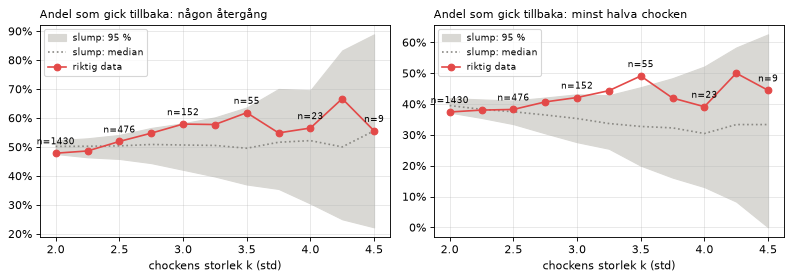

In [13]:
k_values = np.arange(2.0, 4.51, 0.25)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), dpi=80)
for ax, requirement in zip(axes, REQUIREMENTS):
    real, lo, hi, mid, counts = [], [], [], [], []
    for k in k_values:
        rows, cols, sign, size, outcome = shock_list(S_real, SHOCK_L, k, SHOCK_H)
        real.append(share_back(cols, outcome, size, requirement, list(range(M))))
        counts.append(int((~np.isnan(outcome)).sum()))
        null_shares = np.array([share_back(nc, no, ns, requirement, list(range(M)))
                                for _, nc, _, ns, no in (shock_list(S_null[s], SHOCK_L, k, SHOCK_H) for s in range(N_NULL))])
        null_shares = null_shares[~np.isnan(null_shares)]
        lo.append(np.percentile(null_shares, 2.5))
        hi.append(np.percentile(null_shares, 97.5))
        mid.append(np.median(null_shares))
    ax.fill_between(k_values, lo, hi, color="#d9d8d4", label="slump: 95 %")
    ax.plot(k_values, mid, color="#8a8984", linestyle=":", label="slump: median")
    ax.plot(k_values, real, "o-", color=COLORS["rev"], label="riktig data")
    for x, y, n in zip(k_values[::2], real[::2], counts[::2]):
        ax.annotate(f"n={n}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(f"Andel som gick tillbaka: {requirement}", fontsize=10, loc="left")
    ax.set_xlabel("chockens storlek k (std)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Test 4: Är det väntevärdespositivt? Episoder från chock till återgång

Test 2–3 visar *att* priset går tillbaka i snitt. Här kontrollerar vi om det går att **tjäna pengar** på det, en affär i taget:

1. **Start (nivå X):** en chock, alltså en rörelse större än `k` std på `L` dagar. Vi går emot den: kort efter en uppgång, lång efter en nedgång.
2. **Mål (nivå Y):** priset har gått tillbaka minst andelen `Y` av chocken, mätt från chockdagens stängning. Y = 0,5 betyder halva chocken.
3. **Annars:** förluststopp (failsafe, `stop`), tidsgräns (`max_days`) eller slutet av datan (*pågår*, räknas inte).
4. **Tidskonvention som strategin:** signal dag t, in dag t+1, ut dagen efter målet eller stoppen. Kostnad `COST` vid in och ut.
5. Nästa chock i samma tillgång kan bara starta en affär när den förra är stängd.

Resultatet är i **dagliga std** (positionen är volatilitetsskalad). +1 betyder att affären tjänade en normal dagsrörelse.

**Väntevärdet ska vara positivt i båda halvorna av historiken, och bättre än för slumpad data.** Raden *P(slump)* visar hur ofta blandad data ger ett lika högt väntevärde med samma regler.

**Använd:** reglagen, eller till exempel `show_mr_episodes("alla", L=1, k=3.0, retrace=0.5, stop_loss=None, max_days=60)`.

In [14]:
OUTCOME_COLOR = {"nådde Y": "#1baf7a", "förluststopp": "#8a1f1c", "tidsgräns": "#eda100", "pågår": "#8a8984"}
HALF_DATE = dates_x[len(dates_x) // 2]
EPISODE_PERIODS = {"hela": (None, None), "första halvan": (None, HALF_DATE), "andra halvan": (HALF_DATE, None)}


def mr_episodes(L=SHOCK_L, k=SHOCK_K, retrace=EPISODE_Y, stop_loss=STOP_LOSS, max_days=EPISODE_MAX_DAYS,
                cols=None, S=None, cost=COST):
    """En rad per affär: gå emot chocken på rad t, stäng när priset gått tillbaka `retrace` av chocken ('nådde Y'),
    vid orealiserad förlust ≥ stop_loss ('förluststopp'), efter max_days ('tidsgräns') eller vid datans slut ('pågår').
    In till priset rad t+1, ut till priset raden efter beslutet. Enhet: dagliga std."""
    S = S_real if S is None else S
    cols = range(S.shape[1]) if cols is None else cols
    is_shock, direction = find_shocks(S, L, k)
    last = S.shape[0] - 1
    rows = []
    for j in cols:
        free_from = 0
        for t in np.flatnonzero(is_shock[:, j]):
            if t < free_from or t + 2 > last:
                continue
            d = direction[t, j]
            size = d * (S[t, j] - S[t - L, j])
            end, outcome, worst = None, None, 0.0
            for u in range(t + 1, min(t + max_days, last - 1) + 1):
                unrealized = -d * (S[u, j] - S[t + 1, j])
                worst = min(worst, unrealized)
                if stop_loss is not None and unrealized <= -stop_loss:
                    end, outcome = u, "förluststopp"
                    break
                if -d * (S[u, j] - S[t, j]) >= retrace * size:
                    end, outcome = u, "nådde Y"
                    break
            if end is None:
                end = min(t + max_days, last - 1)
                outcome = "tidsgräns" if end - t >= max_days else "pågår"
            gross = -d * (S[end + 1, j] - S[t + 1, j])
            rows.append({"tillgång": instruments[j], "kol": int(j), "rad": int(t), "slutrad": int(end),
                         "start": dates_x[int(t) - 1], "slut": dates_x[int(end) - 1],
                         "riktning": "upp ▲" if d > 0 else "ned ▼", "chock (std)": float(size), "utfall": outcome,
                         "dagar": int(end - t), "värsta_läge": float(min(worst, gross)), "brutto": float(gross),
                         "netto": float(gross - 2 * abs(cost))})
            free_from = end + 1
    schema = {"tillgång": pl.String, "kol": pl.Int64, "rad": pl.Int64, "slutrad": pl.Int64, "start": pl.Date,
              "slut": pl.Date, "riktning": pl.String, "chock (std)": pl.Float64, "utfall": pl.String,
              "dagar": pl.Int64, "värsta_läge": pl.Float64, "brutto": pl.Float64, "netto": pl.Float64}
    return pl.DataFrame(rows, schema=schema)


def finished(ep):
    return ep.filter(pl.col("utfall") != "pågår")


def in_period(ep, a, b):
    return ep.filter((pl.col("start") >= a) if a is not None else pl.lit(True)).filter(
        (pl.col("start") < b) if b is not None else pl.lit(True))


def ev_pvalue(cols, n=None, **kw):
    """Andel slumpade dataset (samma regler) med minst lika högt väntevärde per affär som riktig data."""
    real = finished(mr_episodes(cols=cols, **kw))["netto"].mean()
    null = [finished(mr_episodes(cols=cols, S=S_null[s], **kw))["netto"].mean() for s in range(n or N_NULL)]
    null = np.array([v for v in null if v is not None])
    return float((null >= real).mean()) if real is not None and len(null) else np.nan


def mr_episode_summary(ep, p_value=None):
    """Nyckeltal per period (hela, första halvan, andra halvan). 'pågår' räknas inte."""
    ep = finished(ep)
    table = {}
    for name, (a, b) in EPISODE_PERIODS.items():
        e = in_period(ep, a, b)
        net, hit = e["netto"].to_numpy(), (e["utfall"] == "nådde Y").to_numpy()
        days = e["dagar"].to_numpy()
        n = len(net)
        if n == 0:
            table[name] = ["0"] + ["–"] * 13
            continue
        se = net.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
        f = lambda v, fmt="{:+.2f}": "–" if v is None or np.isnan(v) else fmt.format(v)
        table[name] = [
            str(n),
            f"{hit.mean():.0%}",
            f"{(e['utfall'] == 'förluststopp').to_numpy().mean():.0%}",
            f"{(e['utfall'] == 'tidsgräns').to_numpy().mean():.0%}",
            f(np.median(days[hit]) if hit.any() else np.nan, "{:.0f}"),
            f(np.quantile(days[hit], 0.9) if hit.any() else np.nan, "{:.0f}"),
            f"{(net > 0).mean():.0%}",
            f(net[net > 0].mean() if (net > 0).any() else np.nan),
            f(net[net <= 0].mean() if (net <= 0).any() else np.nan),
            f(net.min()),
            f"{(net[hit] <= 0).mean():.0%}" if hit.any() else "–",
            f(net.mean()),
            f(net.mean() / se if se else np.nan, "{:.2f}"),
            f(net.sum() / max(days.sum(), 1), "{:+.3f}"),
        ]
    labels = ["affärer", "nådde Y", "förluststopp", "tidsgräns", "dagar till Y, median", "dagar till Y, 90 %",
              "andel vinstaffärer", "snittvinst (vinnare)", "snittförlust (förlorare)", "största förlust",
              "nådde Y men förlust", "VÄNTEVÄRDE per affär", "t-värde", "vinst per dag i affär"]
    out = pl.DataFrame({"mått": labels, **table})
    if p_value is not None:
        out = pl.concat([out, pl.DataFrame({"mått": ["P(slump lika bra), hela"], "hela": [f"{p_value:.3f}"],
                                            "första halvan": [""], "andra halvan": [""]})])
    return out


def show_mr_episodes(instrument="alla", L=SHOCK_L, k=SHOCK_K, retrace=EPISODE_Y, stop_loss=STOP_LOSS,
                     max_days=EPISODE_MAX_DAYS, with_null=True):
    """Episoder för en tillgång (eller 'alla'): tidslinje, tid till Y, vinst per affär och nyckeltal."""
    cols = list(range(M)) if instrument == "alla" else [instruments.index(instrument)]
    kw = dict(L=L, k=k, retrace=retrace, stop_loss=stop_loss, max_days=max_days)
    ep = mr_episodes(cols=cols, **kw)
    done = finished(ep)
    if done.is_empty():
        print("Inga avslutade affärer: sänk k eller ändra L.")
        return ep
    fig = plt.figure(figsize=(10, 6.6), dpi=80, layout="constrained")
    grid = fig.add_gridspec(2, 3, height_ratios=[1.1, 1])
    ax = fig.add_subplot(grid[0, :])
    d = dates_x.to_numpy()
    if len(cols) == 1:
        price = prices_x[instruments[cols[0]]].to_numpy()
        ax.plot(d, price, color="k", lw=0.8)
        for e in ep.iter_rows(named=True):
            ax.axvspan(d[e["rad"] - 1], d[e["slutrad"] - 1], color=OUTCOME_COLOR[e["utfall"]], alpha=0.35, lw=0)
            ax.scatter(d[e["rad"] - 1], price[e["rad"] - 1], marker="^" if e["riktning"].startswith("upp") else "v",
                       color=OUTCOME_COLOR[e["utfall"]], s=40, edgecolor="white", zorder=3)
        ax.set_ylabel("pris")
    else:
        for e in ep.iter_rows(named=True):
            ax.plot([d[e["rad"] - 1], d[e["slutrad"] - 1]], [e["kol"], e["kol"]], color=OUTCOME_COLOR[e["utfall"]],
                    lw=6, solid_capstyle="butt")
        ax.set_yticks(range(M), instruments)
        ax.invert_yaxis()
    ax.axvline(HALF_DATE, color="#8a8984", lw=1, ls="--")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.6, label=u) for u, c in OUTCOME_COLOR.items()
               if u in set(ep["utfall"])]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False)
    ax.set_title(f"{instrument}: affärer efter chocker > {k:g} std på {L} d, mål {retrace:.0%} tillbaka, "
                 f"max {max_days} d" + ("" if stop_loss is None else f", stop −{stop_loss:g}"), loc="left", fontsize=10)

    ax1 = fig.add_subplot(grid[1, 0])
    days = np.arange(0, max_days + 1)
    for (name, (a, b)), color in zip(list(EPISODE_PERIODS.items())[1:], ["#2a78d6", "#eb6834"]):
        e = in_period(done, a, b)
        if len(e):
            hit, dd = (e["utfall"] == "nådde Y").to_numpy(), e["dagar"].to_numpy()
            ax1.plot(days, [(hit & (dd <= x)).mean() for x in days], color=color, label=f"{name} (n={len(e)})")
    ax1.set_ylim(0, 1)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax1.set_xlabel("dagar efter chocken")
    ax1.set_title("Andel som nått Y inom d dagar", loc="left", fontsize=10)
    ax1.legend(fontsize=8, loc="lower right")
    ax1.grid(alpha=0.3)

    ax2 = fig.add_subplot(grid[1, 1])
    hit_days = done.filter(pl.col("utfall") == "nådde Y")["dagar"].to_numpy()
    if len(hit_days):
        ax2.hist(hit_days, bins=min(25, max(5, len(hit_days) // 3)), color=OUTCOME_COLOR["nådde Y"], alpha=0.7)
        ax2.axvline(np.median(hit_days), color="k", ls="--", label=f"median {np.median(hit_days):.0f} d")
        ax2.legend(fontsize=8)
    ax2.set_xlabel("dagar")
    ax2.set_title("Tid från X till Y", loc="left", fontsize=10)
    ax2.grid(alpha=0.3)

    ax3 = fig.add_subplot(grid[1, 2])
    net = done["netto"].to_numpy()
    bins = np.linspace(net.min(), net.max(), 25) if len(net) > 1 else 10
    for u in ["nådde Y", "förluststopp", "tidsgräns"]:
        v = done.filter(pl.col("utfall") == u)["netto"].to_numpy()
        if len(v):
            ax3.hist(v, bins=bins, color=OUTCOME_COLOR[u], alpha=0.7, label=u)
    ax3.axvline(0, color="k", lw=0.8)
    ax3.axvline(net.mean(), color="k", ls="--", lw=1.5, label=f"väntevärde {net.mean():+.2f}")
    ax3.set_xlabel("netto per affär (dagliga std)")
    ax3.set_title("Vinst per affär", loc="left", fontsize=10)
    ax3.legend(fontsize=7.5)
    ax3.grid(alpha=0.3)
    plt.show()
    display(mr_episode_summary(ep, ev_pvalue(cols, **kw) if with_null else None))
    return ep

In [15]:
STOP_UI = dict(continuous_update=False, style=STYLE)


def _episodes_ui(instrument, L, k, retrace, stop, max_days):
    show_mr_episodes(instrument, L, k, retrace, None if stop == 0 else stop, max_days)


interact(_episodes_ui,
         instrument=Dropdown(options=["alla"] + instruments, value="alla", description="tillgång", style=STYLE),
         L=IntSlider(value=SHOCK_L, min=1, max=250, description="chockfönster L (dagar)", **STOP_UI),
         k=FloatSlider(value=SHOCK_K, min=1.5, max=5.0, step=0.25, description="X: chock > k std", **STOP_UI),
         retrace=FloatSlider(value=EPISODE_Y, min=0.1, max=1.5, step=0.1, description="Y: andel tillbaka", **STOP_UI),
         stop=FloatSlider(value=STOP_LOSS or 0.0, min=0.0, max=20.0, step=0.5, description="förluststopp (0 = av)",
                          **STOP_UI),
         max_days=IntSlider(value=EPISODE_MAX_DAYS, min=5, max=250, step=5, description="max dagar", **STOP_UI));

interactive(children=(Dropdown(description='tillgång', options=('alla', 'diamonds', 'butter', 'cars', 'cucumbe…

### Förlustsidan: vad händer när priset *inte* går tillbaka, och vad gör en stop?

Samma affärer, men med fokus på **båda sidorna** och på failsafe-nivån (`förluststopp`, i dagliga std):

1. **Varje affär som en stapel** (i tidsordning). Stapeln är slutresultatet, och det svarta strecket visar **hur djupt affären gick** innan den stängdes.
2. **Hur djupt gick affären mot hur slutade den** (utan stop). Allt till höger om stoplinjen skulle ha stoppats. Röda punkter där är **förluster som stoppen begränsar**. Gröna punkter där är **vinnare som stoppen skulle ha klippt**.
3. **Väntevärde mot stopnivå** för båda halvorna av historiken. Leta efter en nivå som hjälper i båda. En nivå som bara hjälper i ena halvan är troligen tur.

En stop utlöses vid stängning och utförs dagen efter, så förlusten kan bli större än stopnivån.

**Använd:** reglagen, eller till exempel `show_mr_risk("alla", stop_loss=3)`.

In [16]:
RISK_LEVELS = [None, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 7.5, 10.0]


def mr_stop_sweep(cols, levels=RISK_LEVELS, **kw):
    """Väntevärde per halva, andel stoppade och förluster för en rad stopnivåer (None = ingen stop)."""
    rows = []
    for level in levels:
        done = finished(mr_episodes(cols=cols, stop_loss=level, **kw))
        net = done["netto"].to_numpy()
        stopped = (done["utfall"] == "förluststopp").to_numpy()
        row = {"stop": "av" if level is None else f"{level:g}", "affärer": len(net),
               "andel stoppade": round(float(stopped.mean()), 2) if len(net) else None,
               "snittvinst": round(float(net[net > 0].mean()), 2) if (net > 0).any() else None,
               "snittförlust": round(float(net[net <= 0].mean()), 2) if (net <= 0).any() else None,
               "största förlust": round(float(net.min()), 2) if len(net) else None}
        for name, (a, b) in list(EPISODE_PERIODS.items()):
            v = in_period(done, a, b)["netto"].to_numpy()
            row[f"väntevärde {name}"] = round(float(v.mean()), 3) if len(v) else None
        rows.append(row)
    return pl.DataFrame(rows)


def show_mr_risk(instrument="alla", L=SHOCK_L, k=SHOCK_K, retrace=EPISODE_Y, stop_loss=3.0,
                 max_days=EPISODE_MAX_DAYS):
    """Båda sidorna: vinster, förluster, hur djupt affärerna gick och vad förluststoppen gör."""
    cols = list(range(M)) if instrument == "alla" else [instruments.index(instrument)]
    kw = dict(L=L, k=k, retrace=retrace, max_days=max_days)
    free = finished(mr_episodes(cols=cols, stop_loss=None, **kw)).sort("start")
    ep = finished(mr_episodes(cols=cols, stop_loss=stop_loss, **kw)).sort("start")
    if ep.is_empty():
        print("Inga avslutade affärer: sänk k eller ändra L.")
        return
    sweep = mr_stop_sweep(cols, **kw)
    stop_text = "ingen stop" if stop_loss is None else f"förluststopp {stop_loss:g} std"

    fig = plt.figure(figsize=(10, 6.8), dpi=80, layout="constrained")
    grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
    ax = fig.add_subplot(grid[0, :])
    x = np.arange(len(ep))
    net, worst = ep["netto"].to_numpy(), ep["värsta_läge"].to_numpy()
    ax.bar(x, net, color=[OUTCOME_COLOR[u] for u in ep["utfall"]], width=0.8)
    ax.vlines(x, worst, 0, color="k", lw=1, label="värsta läge under affären")
    if stop_loss is not None:
        ax.axhline(-stop_loss, color=OUTCOME_COLOR["förluststopp"], ls="--", lw=1, label=f"förluststopp −{stop_loss:g}")
    n_first = int((ep["start"] < HALF_DATE).sum())
    ax.axvline(n_first - 0.5, color="#8a8984", lw=1, ls="--")
    ax.annotate("andra halvan →", (n_first - 0.5, 1), xycoords=("data", "axes fraction"), xytext=(4, -10),
                textcoords="offset points", fontsize=8, color="#8a8984")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("affär (i tidsordning)")
    ax.set_ylabel("netto (dagliga std)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=OUTCOME_COLOR[u], label=u) for u in OUTCOME_COLOR
               if u in set(ep["utfall"])]
    ax.legend(handles=handles + ax.get_legend_handles_labels()[0], loc="upper left", bbox_to_anchor=(1.0, 1.0),
              fontsize=8, frameon=False)
    ax.set_title(f"{instrument}: {stop_text}. Väntevärde {net.mean():+.2f}, största förlust {net.min():.1f}",
                 loc="left", fontsize=10)
    ax.grid(alpha=0.3)

    ax = fig.add_subplot(grid[1, 0])
    depth, final = -free["värsta_läge"].to_numpy(), free["netto"].to_numpy()
    winner = final > 0
    ax.scatter(depth[winner], final[winner], s=18, color=OUTCOME_COLOR["nådde Y"], label="vinnare")
    ax.scatter(depth[~winner], final[~winner], s=18, color="#e34948", label="förlorare")
    ax.axhline(0, color="k", lw=0.8)
    if stop_loss is not None:
        hit = depth >= stop_loss
        ax.axvline(stop_loss, color=OUTCOME_COLOR["förluststopp"], ls="--", lw=1.2)
        ax.axvspan(stop_loss, max(depth.max(), stop_loss) * 1.05, color=OUTCOME_COLOR["förluststopp"], alpha=0.07)
        ax.set_title(f"Stoppen träffar {hit.sum()} av {len(free)} affärer:\n{(hit & ~winner).sum()} förlorare "
                     f"begränsas, {(hit & winner).sum()} vinnare klipps", loc="left", fontsize=10)
    else:
        ax.set_title("Hur djupt gick affären,\noch hur slutade den? (utan stop)", loc="left", fontsize=10)
    ax.set_xlabel("djupaste orealiserade förlust (dagliga std)")
    ax.set_ylabel("netto utan stop")
    ax.legend(fontsize=8, loc="lower left")
    ax.grid(alpha=0.3)

    ax = fig.add_subplot(grid[1, 1])
    labels = sweep["stop"].to_list()
    pos = np.arange(len(labels))
    for col, color in [("väntevärde första halvan", "#2a78d6"), ("väntevärde andra halvan", "#eb6834")]:
        ax.plot(pos, sweep[col].to_numpy(), "o-", color=color, label=col.replace("väntevärde ", ""))
    chosen = "av" if stop_loss is None else f"{stop_loss:g}"
    if chosen in labels:
        ax.axvline(labels.index(chosen), color="k", ls=":", lw=1)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(pos, labels)
    ax.set_xlabel("förluststopp (dagliga std)")
    ax.set_ylabel("väntevärde per affär")
    ax2 = ax.twinx()
    ax2.bar(pos, sweep["andel stoppade"].to_numpy(), color="#8a8984", alpha=0.25, width=0.6)
    ax2.set_ylim(0, 1)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax2.set_ylabel("andel stoppade (staplar)", color="#8a8984")
    ax.set_title("Väntevärde mot stopnivå", loc="left", fontsize=10)
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.3)
    plt.show()

    a, b = mr_episode_summary(free), mr_episode_summary(ep)
    display(pl.DataFrame({"mått": a["mått"], "utan stop": a["hela"], stop_text: b["hela"]}))
    display(sweep)

In [17]:
interact(lambda instrument, L, k, retrace, stop, max_days:
         show_mr_risk(instrument, L, k, retrace, None if stop == 0 else stop, max_days),
         instrument=Dropdown(options=["alla"] + instruments, value="alla", description="tillgång", style=STYLE),
         L=IntSlider(value=SHOCK_L, min=1, max=250, description="chockfönster L (dagar)", **STOP_UI),
         k=FloatSlider(value=SHOCK_K, min=1.5, max=5.0, step=0.25, description="X: chock > k std", **STOP_UI),
         retrace=FloatSlider(value=EPISODE_Y, min=0.1, max=1.5, step=0.1, description="Y: andel tillbaka", **STOP_UI),
         stop=FloatSlider(value=STOP_LOSS or 3.0, min=0.0, max=20.0, step=0.5, description="förluststopp (0 = av)",
                          **STOP_UI),
         max_days=IntSlider(value=EPISODE_MAX_DAYS, min=5, max=250, step=5, description="max dagar", **STOP_UI));

interactive(children=(Dropdown(description='tillgång', options=('alla', 'diamonds', 'butter', 'cars', 'cucumbe…

## Sammanfattning

Tabellen sammanfattar alla tre testerna per tillgång och för alla tillgångar sammanslagna.

| Kolumn | Betydelse |
|---|---|
| **MR-horisonter / trend-horisonter** | Horisonter där autokorrelationen ligger under respektive över slumpbandet (test 1) |
| **längsta MR-område, P** | Hur ofta slumpen ger ett lika långt sammanhängande mean reversion-område för en tillgång (test 1) |
| **chocker** | Antal standardchocker med känt utfall (test 2) |
| **rörelse efter chock** | Genomsnittlig rörelse i chockens riktning, i std. Negativt = gick tillbaka (test 2) |
| **andel tillbaka** | Hur stor andel av chockerna som gick tillbaka. Slumpen ger cirka 50 % (test 3) |
| **P (chock)** | Hur ofta slumpen ger en lika stark rörelse tillbaka (test 2) |
| **väntevärde/affär, P (test 4)** | Genomsnittlig vinst per affär efter kostnad, och hur ofta slumpen ger lika mycket |

**Tumregler för att säga "datan mean revertar":**
- **P under 0,05**, helst även för *bästa av alla tillgångar* om du har letat igenom alla.
- **Fler än cirka 20 oberoende fall.** Långa horisonter och stora chocker ger få fall.
- Effekten håller i **båda halvorna** av historiken, åt **båda hållen** och med **väntetid mellan chocker** (se test 2).
- **Väntevärdet i test 4 är positivt** i båda halvorna av historiken, och förlusterna när det inte går tillbaka är hanterbara (se förlustsidan).
- Om inget av detta stämmer: bygg inte en mean reversion-strategi på datan.

In [18]:
shock_rows, shock_cols, shock_sign, shock_size, shock_outcome = shock_list(S_real, SHOCK_L, SHOCK_K, SHOCK_H)
summary = []
for name, selected in [(c, [j]) for j, c in enumerate(instruments)] + [("ALLA", list(range(M)))]:
    row = {"tillgång": name}
    if len(selected) == 1:
        j = selected[0]
        run = longest_run(ac[:, j] < null_lo)
        row["MR-horisonter"] = ranges(HORIZONS[ac[:, j] < null_lo].tolist())
        row["trend-horisonter"] = ranges(HORIZONS[ac[:, j] > null_hi].tolist())
        row["längsta MR-område, P"] = f"{run} d, P={(null_runs >= run).mean():.3f}" if run else "–"
    else:
        row["MR-horisonter"] = row["trend-horisonter"] = row["längsta MR-område, P"] = ""
    final, p = shock_test(SHOCK_L, SHOCK_K, SHOCK_H, selected)
    row["chocker"] = len(final)
    row["rörelse efter chock (std)"] = round(float(final.mean()), 2) if len(final) else None
    row["andel tillbaka"] = f"{np.mean(final < 0):.0%}" if len(final) else "–"
    row["P (chock)"] = round(p, 3) if len(final) else None
    trades = finished(mr_episodes(cols=selected))["netto"].to_numpy()
    row["väntevärde/affär (test 4)"] = round(float(trades.mean()), 2) if len(trades) else None
    row["P (test 4)"] = round(ev_pvalue(selected), 3) if len(trades) else None
    summary.append(row)
print(f"Standardchock: > {SHOCK_K:g} std på {SHOCK_L} dag(ar), utfall dag t+2 till t+{SHOCK_H + 1}. "
      f"Test 4: mål {EPISODE_Y:.0%} tillbaka, max {EPISODE_MAX_DAYS} d, "
      + ("ingen stop" if STOP_LOSS is None else f"förluststopp {STOP_LOSS:g}") + ", kostnad inräknad")
pl.DataFrame(summary)

Standardchock: > 3 std på 1 dag(ar), utfall dag t+2 till t+21. Test 4: mål 50% tillbaka, max 60 d, ingen stop, kostnad inräknad


tillgång,MR-horisonter,trend-horisonter,"längsta MR-område, P",chocker,rörelse efter chock (std),andel tillbaka,P (chock),väntevärde/affär (test 4),P (test 4)
str,str,str,str,i64,f64,str,f64,f64,f64
"""diamonds""","""130-238""","""–""","""109 d, P=0.016""",26,-2.58,"""62%""",0.0,2.02,0.005
"""butter""","""4-7""","""1, 21-69, 103-107, 110-300""","""4 d, P=0.180""",35,-1.59,"""54%""",0.005,0.2,0.355
"""cars""","""–""","""8-79""","""–""",29,-1.96,"""69%""",0.025,0.33,0.425
"""cucumber""","""–""","""7-8, 10-32""","""–""",24,-0.38,"""42%""",0.39,-0.7,0.74
"""bananas""","""–""","""18-43""","""–""",38,-1.28,"""61%""",0.09,0.64,0.26
"""ALLA""","""""","""""","""""",152,-1.56,"""58%""",0.0,0.52,0.125


## Läget idag: finns det aktiva chocker just nu?

"Idag" betyder **sista dagen i datan**. Avsnittet visar den senaste chocken i varje tillgång och om den fortfarande är **aktiv**, det vill säga om det har gått färre än H dagar sedan den. Under den tiden skulle en mean reversion-strategi ligga **emot** chocken: kort efter en uppgång och lång efter en nedgång.

- **Rörelse (std):** för en aktiv chock är det rörelsen hittills, för en avslutad chock rörelsen under de H dagarna efteråt. Negativ betyder att priset gick tillbaka, positiv att det fortsatte i chockens riktning.
- **Graf:** de senaste dagarna med alla chocker markerade. Skuggat område = perioden då strategin skulle hålla en position.

Med en annan `PRICES_FILE` visar avsnittet läget för den datan.

In [19]:
def shocks_today(L=1, k=3.0, H=20):
    rows, cols, sign, size, outcome = shock_list(S_real, L, k, H)
    last_row = S_real.shape[0] - 1                       # rad efter sista dagen i datan
    table = []
    for j, c in enumerate(instruments):
        m = cols == j
        if not m.any():
            table.append({"tillgång": c, "senaste chock": "–"})
            continue
        r, s, sz, o = rows[m][-1], sign[m][-1], size[m][-1], outcome[m][-1]
        days_since = last_row - r                        # handelsdagar sedan chockdagen
        moved = s * (S_real[last_row, j] - S_real[r, j])
        active = days_since < H
        table.append({
            "tillgång": c,
            "senaste chock": str(dates_x[int(r) - 1]),
            "riktning": "upp ▲" if s > 0 else "ned ▼",
            "storlek (std)": round(float(sz), 1),
            "dagar sedan": int(days_since),
            "status": ("AKTIV: strategin " + ("kort" if s > 0 else "lång") + f", {H - days_since} dagar kvar")
                      if active else "avslutad",
            "rörelse (std)": round(float(moved if active or np.isnan(o) else o), 2),
            "gick tillbaka?": "pågår" if active or np.isnan(o) else ("ja" if o < 0 else "nej"),
        })
    return pl.DataFrame(table)


def plot_today(L=1, k=3.0, H=20, days_back=250):
    rows, cols, sign, size, outcome = shock_list(S_real, L, k, H)
    n = len(instruments)
    start = max(len(dates_x) - days_back, 0)
    d = dates_x.to_numpy()
    fig, axes = plt.subplots(n, 1, figsize=(10, 2.0 * n + 0.8), dpi=80, sharex=True, squeeze=False)
    for ax, (j, c) in zip(axes[:, 0], enumerate(instruments)):
        price = prices_x[c].to_numpy()
        ax.plot(d[start:], price[start:], color="k", linewidth=1)
        m = (cols == j) & (rows - 1 >= start)
        for r, s, o, sz in zip(rows[m], sign[m], outcome[m], size[m]):
            day = r - 1
            if np.isnan(o):
                color = COLORS["none"]
                ax.axvspan(d[day], d[min(day + H, len(d) - 1)], color="#f6d3d3", alpha=0.6, zorder=0)
            else:
                color = COLORS["rev"] if went_back(o, sz, REQUIREMENTS[0]) else COLORS["trend"]
            ax.scatter(d[day], price[day], marker="^" if s > 0 else "v", color=color, s=60,
                       edgecolor="white", zorder=3)
        ax.set_title(c, fontsize=10, loc="left")
        ax.set_ylabel("pris")
        ax.grid(alpha=0.3)
    handles = [Line2D([], [], marker="o", linestyle="", color=COLORS["rev"], label="gick tillbaka"),
               Line2D([], [], marker="o", linestyle="", color=COLORS["trend"], label="fortsatte"),
               Line2D([], [], marker="o", linestyle="", color=COLORS["none"], label="pågår (utfall okänt)"),
               plt.Rectangle((0, 0), 1, 1, color="#f6d3d3", label="strategin håller position")]
    fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 0.965), ncols=4, fontsize=8, frameon=False)
    fig.suptitle(f"Läget {dates_x[-1]}: chocker > {k:g} std på {L} dag(ar), hålltid {H} dagar",
                 fontsize=12, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()
    display(shocks_today(L, k, H))


interact(plot_today,
         L=IntSlider(value=SHOCK_L, min=1, max=250, description="chockfönster L (dagar)", style=STYLE,
                     continuous_update=False),
         k=FloatSlider(value=SHOCK_K, min=1.5, max=5.0, step=0.25, description="gräns k (std)", style=STYLE,
                       continuous_update=False),
         H=IntSlider(value=SHOCK_H, min=1, max=250, description="hålltid H (dagar)", style=STYLE,
                     continuous_update=False),
         days_back=IntSlider(value=250, min=40, max=len(dates_x), step=10, description="visa dagar bakåt",
                             style=STYLE, continuous_update=False));

interactive(children=(IntSlider(value=1, continuous_update=False, description='chockfönster L (dagar)', max=25…